# Vision Transformer (ViT) for Skin Lesion Classification
## HAM10000 Dataset — Trained from Scratch

This notebook implements a Vision Transformer (ViT) trained **from scratch** (no pretrained weights) on the HAM10000 dermoscopic skin lesion dataset.  
The architecture uses a **two-stage hierarchical classification pipeline**:
- **Stage 1**: Binary classifier — Benign vs Malignant
- **Stage 2**: Multi-class classifier — MEL vs BCC vs AKIEC (malignant subtypes only)

Both stages share the same ViT backbone (CLS token output). This notebook is part of a group project comparing ViT against MobileNetV2.

---
## Section 1: Imports and Setup

We import all required libraries, configure the device (GPU with CUDA if available), and set random seeds for full reproducibility across PyTorch, NumPy, and Python's random module.

In [1]:
import os
import random
import math
import json
import shutil
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image
from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_curve, auc, f1_score, precision_score,
    recall_score, accuracy_score
)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as transforms
from torchvision.utils import make_grid

# ── Mixed precision AMP — compatibility shim ─────────────────────────────────
# torch.cuda.amp.autocast / GradScaler were deprecated in PyTorch 2.3 and
# removed in 2.4+. This shim provides autocast() and GradScaler() that work
# with any PyTorch >= 1.10.
_amp_device = 'cuda' if torch.cuda.is_available() else 'cpu'
try:
    from torch.amp import autocast as _autocast_base, GradScaler as _GradScaler_base
    def autocast():
        return _autocast_base(device_type=_amp_device)
    def GradScaler():
        return _GradScaler_base(_amp_device)
    print('AMP: using torch.amp (PyTorch 1.10+ API)')
except (ImportError, AttributeError):
    from torch.cuda.amp import autocast, GradScaler
    print('AMP: using torch.cuda.amp (legacy API)')

# ── Reproducibility ─────────────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ── Device ──────────────────────────────────────────────────────────────────────────
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

# ── Output directories ────────────────────────────────────────────────────────────
FIGURES_DIR     = Path('figures')
CHECKPOINTS_DIR = Path('checkpoints')
FIGURES_DIR.mkdir(exist_ok=True)
CHECKPOINTS_DIR.mkdir(exist_ok=True)

print('Output directories created.')

AMP: using torch.amp (PyTorch 1.10+ API)
Using device: cuda
GPU: NVIDIA GeForce RTX 5070 Laptop GPU
VRAM: 8.5 GB
Output directories created.


---
## Section 2: Data Loading and Exploration

### Dataset paths

The HAM10000 dataset is provided as two flat image folders plus a metadata CSV.  
We first build a unified DataFrame mapping each `image_id` to its file path and class label, then split by **lesion_id** (not image_id) to prevent data leakage — images from the same lesion must not appear in both train and validation sets.

Split ratios: **70% train / 15% validation / 15% test**, stratified by class.

In [2]:
# ── Configure paths — edit these to match your system ────────────────────────
ARCHIVE_DIR   = Path(r'C:/Users/Haruna/Downloads/archive')
METADATA_CSV  = ARCHIVE_DIR / 'HAM10000_metadata.csv'
IMG_DIRS      = [
    ARCHIVE_DIR / 'HAM10000_images_part_1',
    ARCHIVE_DIR / 'HAM10000_images_part_2',
]

# ── Class definitions ─────────────────────────────────────────────────────────
# 7 original HAM10000 classes (lowercase as in the CSV)
CLASS_NAMES = ['mel', 'nv', 'bcc', 'akiec', 'bkl', 'df', 'vasc']

# Two-stage hierarchy
BENIGN_CLASSES    = ['nv', 'bkl', 'df', 'vasc']   # Stage 1 label = 0
MALIGNANT_CLASSES = ['mel', 'bcc', 'akiec']         # Stage 1 label = 1

# Stage 2 sub-labels for malignant classes
MAL_SUBCLASS = {'mel': 0, 'bcc': 1, 'akiec': 2}
MAL_SUBCLASS_NAMES = ['MEL', 'BCC', 'AKIEC']

STAGE1_LABELS = {c: 0 for c in BENIGN_CLASSES}
STAGE1_LABELS.update({c: 1 for c in MALIGNANT_CLASSES})

# ── Build master DataFrame ────────────────────────────────────────────────────
meta = pd.read_csv(METADATA_CSV)
print(f'Total records in metadata: {len(meta)}')

# Build image_id → path lookup
img_lookup = {}
for img_dir in IMG_DIRS:
    for p in img_dir.glob('*.jpg'):
        img_lookup[p.stem] = str(p)

meta['filepath'] = meta['image_id'].map(img_lookup)
missing = meta['filepath'].isna().sum()
print(f'Images found: {len(meta) - missing} / {len(meta)}')
meta = meta.dropna(subset=['filepath']).copy()

meta['stage1_label'] = meta['dx'].map(STAGE1_LABELS)
meta['stage2_label'] = meta['dx'].map(MAL_SUBCLASS)  # NaN for benign

print(f'\nClass distribution:')
print(meta['dx'].value_counts())
print(f'\nStage 1 (benign=0, malignant=1):')
print(meta['stage1_label'].value_counts())

Total records in metadata: 10015
Images found: 10015 / 10015

Class distribution:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

Stage 1 (benign=0, malignant=1):
stage1_label
0    8061
1    1954
Name: count, dtype: int64


In [3]:
# ── Train / Val / Test split ──────────────────────────────────────────────────
# Split by lesion_id to avoid leakage (same lesion in train AND val).
# We assign a representative class to each lesion (most common dx across its images).

lesion_df = (
    meta.groupby('lesion_id')['dx']
    .agg(lambda x: x.mode()[0])
    .reset_index()
    .rename(columns={'dx': 'lesion_dx'})
)

# 70 / 15 / 15 split on lesion level
train_lesions, temp_lesions = train_test_split(
    lesion_df['lesion_id'].values,
    test_size=0.30,
    stratify=lesion_df['lesion_dx'].values,
    random_state=SEED
)

temp_dx = lesion_df[lesion_df['lesion_id'].isin(temp_lesions)]['lesion_dx'].values
val_lesions, test_lesions = train_test_split(
    temp_lesions,
    test_size=0.50,
    stratify=temp_dx,
    random_state=SEED
)

train_df = meta[meta['lesion_id'].isin(train_lesions)].reset_index(drop=True)
val_df   = meta[meta['lesion_id'].isin(val_lesions)].reset_index(drop=True)
test_df  = meta[meta['lesion_id'].isin(test_lesions)].reset_index(drop=True)

print(f'Train images : {len(train_df)}')
print(f'Val   images : {len(val_df)}')
print(f'Test  images : {len(test_df)}')
print(f'\nTrain class distribution:')
print(train_df['dx'].value_counts())

Train images : 6981
Val   images : 1515
Test  images : 1519

Train class distribution:
dx
nv       4683
mel       773
bkl       772
bcc       361
akiec     222
vasc       99
df         71
Name: count, dtype: int64


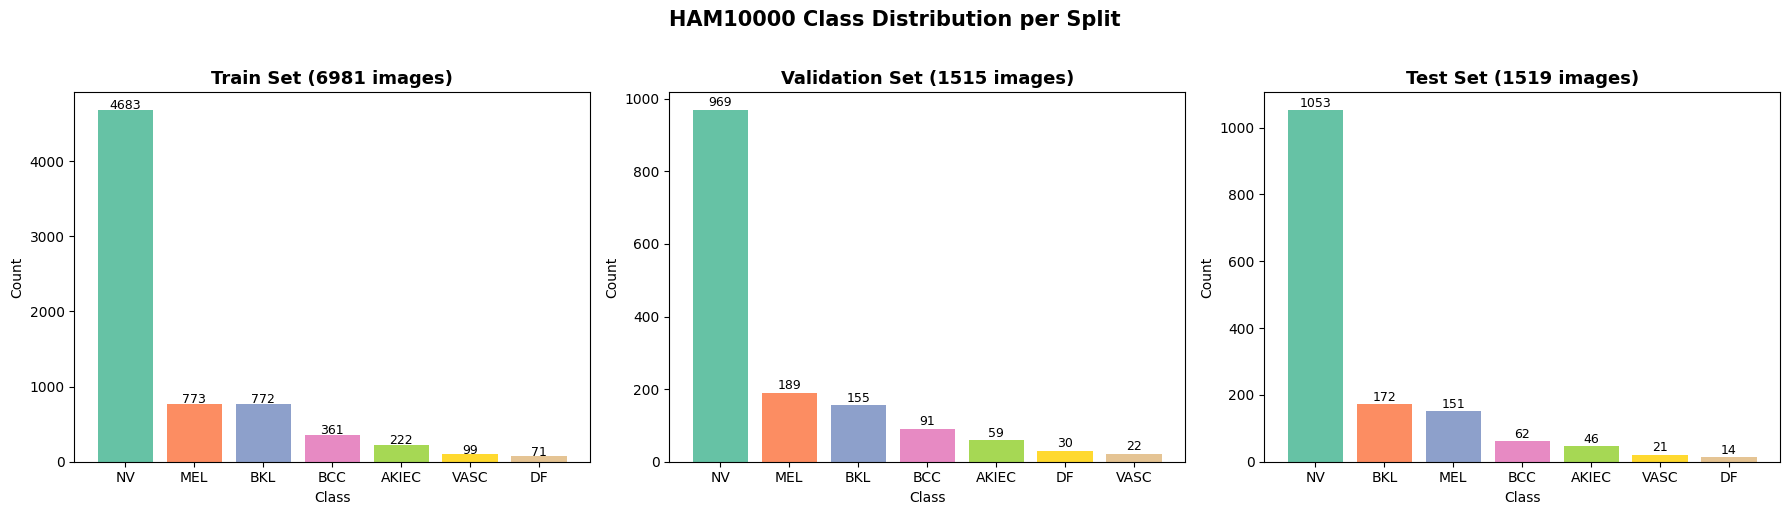

Saved: figures/class_distribution.png


In [4]:
# ── Visualise class distribution ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
palette = sns.color_palette('Set2', 7)

for ax, (df, title) in zip(axes, [
    (train_df, 'Train'), (val_df, 'Validation'), (test_df, 'Test')
]):
    counts = df['dx'].value_counts()
    ax.bar(counts.index.str.upper(), counts.values, color=palette)
    ax.set_title(f'{title} Set ({len(df)} images)', fontsize=13, fontweight='bold')
    ax.set_xlabel('Class')
    ax.set_ylabel('Count')
    for i, v in enumerate(counts.values):
        ax.text(i, v + 10, str(v), ha='center', fontsize=9)

plt.suptitle('HAM10000 Class Distribution per Split', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures/class_distribution.png')

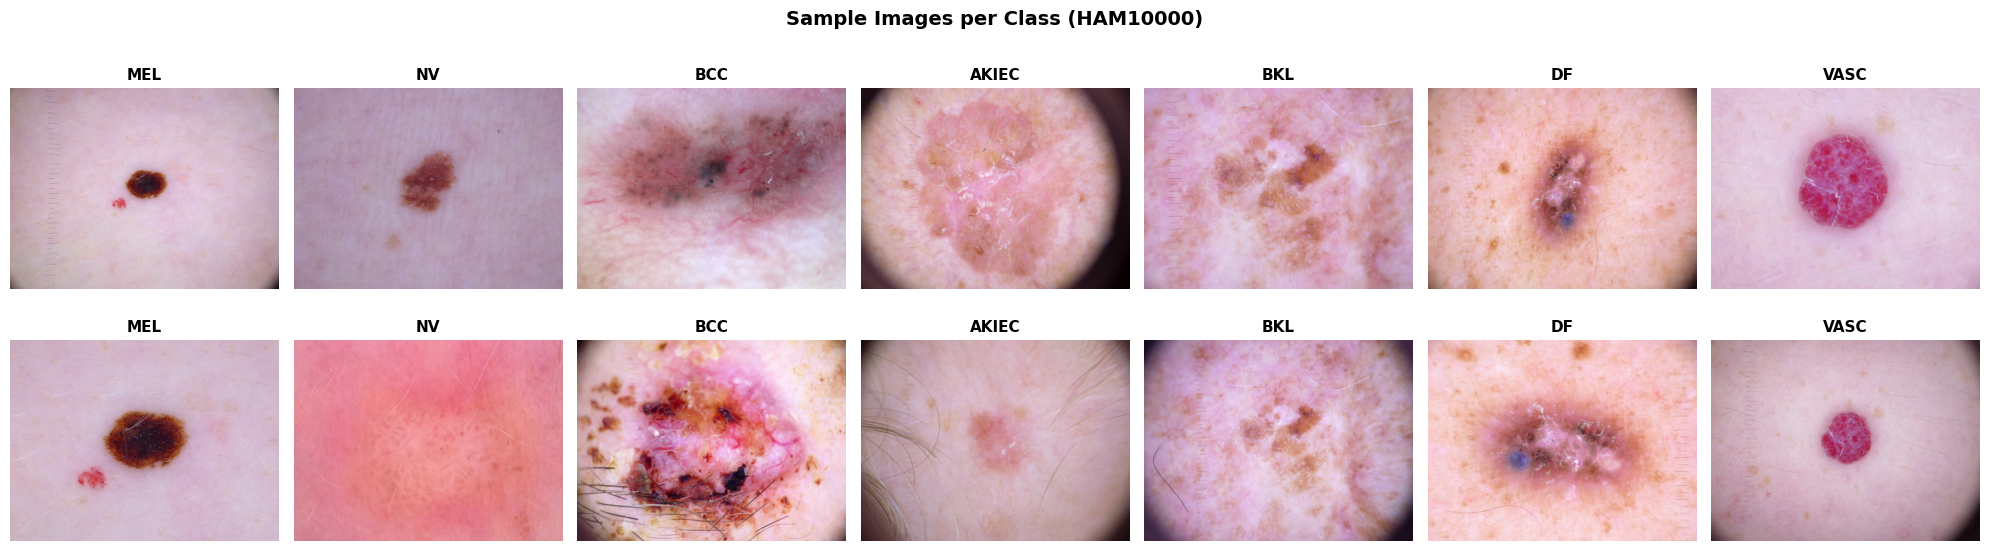

Saved: figures/sample_images.png


In [5]:
# ── Display sample images ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 7, figsize=(20, 6))
for col, cls in enumerate(CLASS_NAMES):
    samples = train_df[train_df['dx'] == cls].head(2)
    for row, (_, row_data) in enumerate(samples.iterrows()):
        img = Image.open(row_data['filepath']).convert('RGB')
        axes[row, col].imshow(img)
        axes[row, col].set_title(cls.upper(), fontsize=11, fontweight='bold')
        axes[row, col].axis('off')

plt.suptitle('Sample Images per Class (HAM10000)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'sample_images.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures/sample_images.png')

---
## Section 3: Data Preprocessing and Augmentation

### Why these augmentations?

Training from scratch on ~7K images risks overfitting. We use aggressive but clinically plausible augmentations:
- **Random flips**: Lesion orientation is arbitrary in dermoscopy
- **Random rotation (±30°)**: Captures all orientations without distorting lesion shape
- **Color jitter**: Lighting and device variability between clinics
- **Random resized crop**: Forces the model to recognise lesions at varying scales

Validation/test only use deterministic transforms (resize + center crop) to ensure fair evaluation.

### Class weights for imbalanced data

NV dominates with ~67% of images. We compute inverse-frequency class weights so the loss function penalises errors on rare classes more heavily.

In [6]:
# ── ImageNet normalisation constants ─────────────────────────────────────────
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

val_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

print('Transforms defined.')

Transforms defined.


In [7]:
# ── Custom Dataset class ───────────────────────────────────────────────────────
# The dataset returns BOTH stage1 and stage2 labels.
# Stage 2 label is -1 for benign images (ignored during stage 2 training).

class SkinLesionDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df        = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row['filepath']).convert('RGB')
        if self.transform:
            image = self.transform(image)

        stage1 = int(row['stage1_label'])         # 0=benign, 1=malignant
        stage2 = int(row['stage2_label']) if not pd.isna(row['stage2_label']) else -1
        return image, stage1, stage2


train_dataset = SkinLesionDataset(train_df, transform=train_transform)
val_dataset   = SkinLesionDataset(val_df,   transform=val_transform)
test_dataset  = SkinLesionDataset(test_df,  transform=val_transform)

print(f'Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}')

Train: 6981 | Val: 1515 | Test: 1519


In [8]:
# ── Class weights for Stage 1 (benign vs malignant) ───────────────────────────
# Inverse-frequency weighting: rare classes get higher weight.

s1_counts = train_df['stage1_label'].value_counts().sort_index()  # [benign_count, mal_count]
s1_total  = s1_counts.sum()
s1_weights = torch.tensor(
    [s1_total / (2 * s1_counts[i]) for i in range(2)],
    dtype=torch.float32
).to(device)
print(f'Stage 1 class weights (benign, malignant): {s1_weights.cpu().numpy().round(3)}')

# ── Class weights for Stage 2 (MEL / BCC / AKIEC) ────────────────────────────
mal_train = train_df[train_df['stage1_label'] == 1]
s2_counts = mal_train['stage2_label'].value_counts().sort_index()  # 0=MEL,1=BCC,2=AKIEC
s2_total  = s2_counts.sum()
s2_weights = torch.tensor(
    [s2_total / (3 * s2_counts[i]) for i in range(3)],
    dtype=torch.float32
).to(device)
print(f'Stage 2 class weights (MEL, BCC, AKIEC):   {s2_weights.cpu().numpy().round(3)}')

# ── DataLoaders ───────────────────────────────────────────────────────────────
BATCH_SIZE   = 8
NUM_WORKERS  = 0  # Use 0 on Windows; increase to 2-4 on Linux/macOS

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

print(f'\nBatch size: {BATCH_SIZE}')
print(f'Train batches: {len(train_loader)}')

Stage 1 class weights (benign, malignant): [0.621 2.574]
Stage 2 class weights (MEL, BCC, AKIEC):   [0.585 1.252 2.036]

Batch size: 8
Train batches: 872


---
## Section 4: Model Architecture — Vision Transformer from Scratch

### Why a smaller ViT?

The standard ViT-B/16 has 86M parameters and was designed for ImageNet (1.28M images). Training it from scratch on ~7K images would lead to severe overfitting. We use a **scaled-down ViT** with:
- `embed_dim=256` (vs 768 in ViT-B)
- `depth=6` transformer blocks (vs 12)
- `num_heads=8`, `ffn_dim=512`

This yields ~5–7M parameters — comparable in scale to MobileNetV2 — and is far more appropriate for the dataset size.

### Architecture overview

```
Input (B, 3, 224, 224)
    → PatchEmbedding (Conv2d stride 16) → (B, 196, 256)
    → Prepend CLS token              → (B, 197, 256)
    → Add positional embeddings      → (B, 197, 256)
    → 6× TransformerBlock            → (B, 197, 256)
    → Extract CLS token              → (B, 256)
    → Stage1Head: Linear(256, 2)     → benign/malignant logits
    → Stage2Head: Linear(256, 3)     → MEL/BCC/AKIEC logits
```

In [9]:
# ── 4.1 Patch Embedding ────────────────────────────────────────────────────────
# We use a Conv2d with kernel_size=patch_size and stride=patch_size.
# For a 224×224 image with patch_size=16: (224/16)² = 196 patches.
# This is equivalent to, but faster than, manually slicing patches and applying a linear layer.

class PatchEmbedding(nn.Module):
    """
    Split image into non-overlapping patches and project each patch
    to embed_dim using a convolutional layer.
    """
    def __init__(self, img_size=224, patch_size=16, in_channels=3, embed_dim=256):
        super().__init__()
        self.num_patches = (img_size // patch_size) ** 2  # 196
        self.proj = nn.Conv2d(
            in_channels, embed_dim,
            kernel_size=patch_size, stride=patch_size
        )

    def forward(self, x):
        # x: (B, C, H, W) → (B, embed_dim, H/P, W/P) → (B, num_patches, embed_dim)
        x = self.proj(x)             # (B, embed_dim, 14, 14)
        x = x.flatten(2)            # (B, embed_dim, 196)
        x = x.transpose(1, 2)       # (B, 196, embed_dim)
        return x


# Quick sanity check
_dummy = torch.zeros(2, 3, 224, 224)
_pe = PatchEmbedding()
assert _pe(_dummy).shape == (2, 196, 256), 'PatchEmbedding shape mismatch'
print('PatchEmbedding OK — output shape:', _pe(_dummy).shape)

PatchEmbedding OK — output shape: torch.Size([2, 196, 256])


In [10]:
# ── 4.2 Multi-Head Self-Attention ──────────────────────────────────────────────
# Standard scaled dot-product attention.
# We store the attention weights so we can extract them for Attention Rollout later.

class MultiHeadSelfAttention(nn.Module):
    """
    Multi-head self-attention with optional attention weight storage
    for Attention Rollout visualisation.
    """
    def __init__(self, embed_dim=256, num_heads=8, attn_dropout=0.1):
        super().__init__()
        assert embed_dim % num_heads == 0, 'embed_dim must be divisible by num_heads'

        self.num_heads  = num_heads
        self.head_dim   = embed_dim // num_heads
        self.scale      = self.head_dim ** -0.5  # 1/√d_k

        self.qkv        = nn.Linear(embed_dim, embed_dim * 3, bias=False)
        self.proj       = nn.Linear(embed_dim, embed_dim)
        self.attn_drop  = nn.Dropout(attn_dropout)

        # Attention weights stored here during forward pass
        self.attn_weights = None

    def forward(self, x):
        B, N, C = x.shape  # (batch, num_tokens, embed_dim)

        # Project to Q, K, V
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)   # (3, B, heads, N, head_dim)
        q, k, v = qkv.unbind(0)             # each: (B, heads, N, head_dim)

        # Scaled dot-product attention
        attn = (q @ k.transpose(-2, -1)) * self.scale  # (B, heads, N, N)
        attn = attn.softmax(dim=-1)
        self.attn_weights = attn.detach()   # Save for rollout
        attn = self.attn_drop(attn)

        # Weighted sum of values
        x = (attn @ v).transpose(1, 2).reshape(B, N, C)
        x = self.proj(x)
        return x


print('MultiHeadSelfAttention defined.')

MultiHeadSelfAttention defined.


In [11]:
# ── 4.3 Transformer Block ──────────────────────────────────────────────────────
# Each block follows the Pre-Norm design (LayerNorm before attention and FFN),
# which is more stable for training from scratch than Post-Norm.

class TransformerBlock(nn.Module):
    """
    Transformer encoder block:
        x = x + MHSA(LayerNorm(x))      ← attention sub-layer with residual
        x = x + FFN(LayerNorm(x))       ← feed-forward sub-layer with residual
    """
    def __init__(self, embed_dim=256, num_heads=8, ffn_dim=512,
                 attn_dropout=0.1, ffn_dropout=0.1):
        super().__init__()

        # Attention sub-layer
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn  = MultiHeadSelfAttention(embed_dim, num_heads, attn_dropout)

        # Feed-forward sub-layer
        self.norm2 = nn.LayerNorm(embed_dim)
        self.ffn   = nn.Sequential(
            nn.Linear(embed_dim, ffn_dim),
            nn.GELU(),
            nn.Dropout(ffn_dropout),
            nn.Linear(ffn_dim, embed_dim),
            nn.Dropout(ffn_dropout),
        )

    def forward(self, x):
        x = x + self.attn(self.norm1(x))   # Residual + attention
        x = x + self.ffn(self.norm2(x))    # Residual + FFN
        return x


print('TransformerBlock defined.')

TransformerBlock defined.


In [12]:
# ── 4.4 Vision Transformer Backbone ──────────────────────────────────────────
# The backbone produces a CLS token embedding that is shared by both
# Stage 1 and Stage 2 classification heads.

class VisionTransformer(nn.Module):
    """
    Small Vision Transformer (ViT) trained from scratch.

    Config (scaled down for ~7K training images):
        embed_dim   = 256  (vs 768 in ViT-B)
        depth       = 6    (vs 12 in ViT-B)
        num_heads   = 8
        ffn_dim     = 512  (vs 3072 in ViT-B)

    Output: CLS token embedding of shape (B, embed_dim)
    """
    def __init__(
        self,
        img_size=224, patch_size=16, in_channels=3,
        embed_dim=256, depth=6, num_heads=8, ffn_dim=512,
        attn_dropout=0.1, ffn_dropout=0.1
    ):
        super().__init__()

        self.embed_dim    = embed_dim
        self.patch_embed  = PatchEmbedding(img_size, patch_size, in_channels, embed_dim)
        num_patches       = self.patch_embed.num_patches  # 196

        # Learnable CLS token prepended to the patch sequence
        self.cls_token    = nn.Parameter(torch.zeros(1, 1, embed_dim))

        # Learnable 1D positional embeddings for [CLS + 196 patches] = 197 tokens
        self.pos_embed    = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))

        self.pos_drop     = nn.Dropout(0.1)

        # Stack of transformer encoder blocks
        self.blocks       = nn.ModuleList([
            TransformerBlock(embed_dim, num_heads, ffn_dim, attn_dropout, ffn_dropout)
            for _ in range(depth)
        ])

        self.norm         = nn.LayerNorm(embed_dim)

        # Weight initialisation (important for training from scratch)
        self._init_weights()

    def _init_weights(self):
        # Initialise positional embeddings and CLS token with small values
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.LayerNorm):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight)

    def forward(self, x):
        B = x.shape[0]

        # 1. Patch embedding → (B, 196, embed_dim)
        x = self.patch_embed(x)

        # 2. Prepend CLS token → (B, 197, embed_dim)
        cls = self.cls_token.expand(B, -1, -1)
        x   = torch.cat([cls, x], dim=1)

        # 3. Add positional embeddings
        x = self.pos_drop(x + self.pos_embed)

        # 4. Pass through transformer blocks
        for block in self.blocks:
            x = block(x)

        x = self.norm(x)

        # 5. Return CLS token (index 0) as the image representation
        return x[:, 0]  # (B, embed_dim)


# Sanity check
vit_check = VisionTransformer()
_dummy = torch.zeros(2, 3, 224, 224)
assert vit_check(_dummy).shape == (2, 256), 'ViT output shape mismatch'
total_params = sum(p.numel() for p in vit_check.parameters())
print(f'ViT backbone parameters: {total_params:,}  (~{total_params/1e6:.1f}M)')
del vit_check

ViT backbone parameters: 3,406,080  (~3.4M)


In [13]:
# ── 4.5 Full Two-Stage Model ──────────────────────────────────────────────────
# The ViT backbone is shared. Two independent linear heads read from the CLS token.
# Stage 1: benign (0) vs malignant (1)
# Stage 2: MEL (0) vs BCC (1) vs AKIEC (2) — only applied to malignant predictions

class TwoStageViT(nn.Module):
    """
    Full two-stage hierarchical ViT for skin lesion classification.

    forward() returns (stage1_logits, stage2_logits) from the same CLS token.
    During inference, Stage 2 logits are only meaningful when Stage 1 predicts malignant.
    """
    def __init__(self, embed_dim=256, **vit_kwargs):
        super().__init__()

        self.backbone   = VisionTransformer(embed_dim=embed_dim, **vit_kwargs)

        # Stage 1: binary head
        self.stage1_head = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Linear(embed_dim, 2)
        )

        # Stage 2: malignant sub-type head
        self.stage2_head = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Linear(embed_dim, 3)
        )

    def forward(self, x):
        cls_token = self.backbone(x)            # (B, embed_dim)
        logits1   = self.stage1_head(cls_token) # (B, 2)
        logits2   = self.stage2_head(cls_token) # (B, 3)
        return logits1, logits2

    def get_attention_weights(self):
        """Retrieve attention weights from all transformer blocks (for Attention Rollout)."""
        return [block.attn.attn_weights for block in self.backbone.blocks]


# Instantiate model
model = TwoStageViT(
    embed_dim=256, depth=6, num_heads=8, ffn_dim=512,
    attn_dropout=0.1, ffn_dropout=0.1
).to(device)

total_params = sum(p.numel() for p in model.parameters())
print(f'Total model parameters: {total_params:,}  (~{total_params/1e6:.1f}M)')

# Verify forward pass
_dummy = torch.zeros(2, 3, 224, 224).to(device)
with torch.no_grad():
    _l1, _l2 = model(_dummy)
print(f'Stage 1 logits shape: {_l1.shape}')  # (2, 2)
print(f'Stage 2 logits shape: {_l2.shape}')  # (2, 3)

Total model parameters: 3,408,389  (~3.4M)
Stage 1 logits shape: torch.Size([2, 2])
Stage 2 logits shape: torch.Size([2, 3])


---
## Section 5: Training Loop

### Training strategy

We train in three phases:

1. **Stage 1 training** (all images): Backbone + Stage 1 head are trained together to classify benign vs malignant. Uses weighted cross-entropy to handle the severe NV imbalance.

2. **Stage 2 training** (malignant images only): Backbone is frozen. Only the Stage 2 head is trained on MEL/BCC/AKIEC images.

3. **Joint fine-tuning** (optional): Both backbone and both heads are unfrozen with a smaller learning rate for end-to-end refinement.

### Memory efficiency

- **Mixed precision** (`torch.cuda.amp`): fp16 forward/backward pass, fp32 master weights — approximately halves VRAM usage.
- **Gradient accumulation over 4 steps**: Effective batch size = 8 × 4 = 32 without loading 32 images simultaneously.

### Learning rate schedule

Linear warmup (5 epochs) followed by cosine annealing. Warmup avoids large gradient updates at initialisation when attention weights are random.

In [14]:
# ── Training hyperparameters ──────────────────────────────────────────────────
EPOCHS_STAGE1   = 40
EPOCHS_STAGE2   = 25
EPOCHS_FINETUNE = 15
LR_STAGE1       = 1e-3
LR_STAGE2       = 5e-4
LR_FINETUNE     = 2e-4
WEIGHT_DECAY    = 0.05
WARMUP_EPOCHS   = 5
ACCUM_STEPS     = 4   # Gradient accumulation steps


def get_lr_scheduler(optimizer, warmup_epochs, total_epochs, steps_per_epoch):
    """
    Linear warmup for `warmup_epochs`, then cosine annealing to near-zero.
    Operates at step level (not epoch level) for smooth scheduling.
    """
    warmup_steps = warmup_epochs * steps_per_epoch
    total_steps  = total_epochs  * steps_per_epoch

    def lr_lambda(step):
        if step < warmup_steps:
            return float(step) / max(1, warmup_steps)
        progress = float(step - warmup_steps) / max(1, total_steps - warmup_steps)
        return max(0.0, 0.5 * (1.0 + math.cos(math.pi * progress)))

    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


print('Training config defined.')

Training config defined.


In [15]:
# ── Metric helpers ────────────────────────────────────────────────────────────
from sklearn.metrics import f1_score as sk_f1

def compute_weighted_f1(y_true, y_pred, n_classes):
    return sk_f1(y_true, y_pred, average='weighted', labels=list(range(n_classes)), zero_division=0)


# ── Stage 1 validation ────────────────────────────────────────────────────────
@torch.no_grad()
def validate_stage1(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    total_loss = 0.0
    criterion  = nn.CrossEntropyLoss(weight=s1_weights)

    for imgs, s1_labels, _ in loader:
        imgs      = imgs.to(device)
        s1_labels = s1_labels.to(device)

        with autocast():
            logits1, _ = model(imgs)
            loss = criterion(logits1, s1_labels)

        total_loss += loss.item() * len(imgs)
        preds = logits1.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(s1_labels.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    wf1      = compute_weighted_f1(all_labels, all_preds, 2)
    acc      = accuracy_score(all_labels, all_preds)
    return avg_loss, wf1, acc, all_labels, all_preds


# ── Stage 2 validation ────────────────────────────────────────────────────────
@torch.no_grad()
def validate_stage2(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    total_loss = 0.0
    criterion  = nn.CrossEntropyLoss(weight=s2_weights)

    for imgs, s1_labels, s2_labels in loader:
        # Only evaluate on malignant images (s2_label >= 0)
        mask = s2_labels >= 0
        if mask.sum() == 0:
            continue

        imgs      = imgs[mask].to(device)
        s2_labels = s2_labels[mask].to(device)

        with autocast():
            _, logits2 = model(imgs)
            loss = criterion(logits2, s2_labels)

        total_loss += loss.item() * len(imgs)
        preds = logits2.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(s2_labels.cpu().numpy())

    if len(all_labels) == 0:
        return 0.0, 0.0, 0.0, [], []
    avg_loss = total_loss / len(all_labels)
    wf1      = compute_weighted_f1(all_labels, all_preds, 3)
    acc      = accuracy_score(all_labels, all_preds)
    return avg_loss, wf1, acc, all_labels, all_preds


print('Validation helpers defined.')

Validation helpers defined.


In [16]:
# ── Stage 1 Training ──────────────────────────────────────────────────────────
# Train BOTH backbone + Stage 1 head (Stage 2 head is also updated but not evaluated).

criterion_s1 = nn.CrossEntropyLoss(weight=s1_weights)
optimizer_s1 = optim.AdamW(model.parameters(), lr=LR_STAGE1, weight_decay=WEIGHT_DECAY)
scaler_s1    = GradScaler()
scheduler_s1 = get_lr_scheduler(optimizer_s1, WARMUP_EPOCHS, EPOCHS_STAGE1, len(train_loader))

history_s1 = {'train_loss': [], 'val_loss': [], 'val_f1': [], 'val_acc': [], 'lr': []}
best_s1_f1 = 0.0
global_step = 0

print(f'Starting Stage 1 training for {EPOCHS_STAGE1} epochs...')
print(f'Effective batch size: {BATCH_SIZE * ACCUM_STEPS} (accumulation steps: {ACCUM_STEPS})')

for epoch in range(1, EPOCHS_STAGE1 + 1):
    model.train()
    epoch_loss   = 0.0
    num_batches  = 0

    optimizer_s1.zero_grad()

    for step, (imgs, s1_labels, _) in enumerate(train_loader):
        imgs      = imgs.to(device, non_blocking=True)
        s1_labels = s1_labels.to(device, non_blocking=True)

        with autocast():
            logits1, _ = model(imgs)
            loss = criterion_s1(logits1, s1_labels) / ACCUM_STEPS

        scaler_s1.scale(loss).backward()

        # Optimizer step every ACCUM_STEPS mini-batches
        if (step + 1) % ACCUM_STEPS == 0 or (step + 1) == len(train_loader):
            scaler_s1.unscale_(optimizer_s1)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler_s1.step(optimizer_s1)
            scaler_s1.update()
            optimizer_s1.zero_grad()
            scheduler_s1.step()
            global_step += 1

        epoch_loss  += loss.item() * ACCUM_STEPS
        num_batches += 1

    # ── Validation ────────────────────────────────────────────────────────────
    train_loss = epoch_loss / num_batches
    val_loss, val_f1, val_acc, _, _ = validate_stage1(model, val_loader)
    current_lr = optimizer_s1.param_groups[0]['lr']

    history_s1['train_loss'].append(train_loss)
    history_s1['val_loss'].append(val_loss)
    history_s1['val_f1'].append(val_f1)
    history_s1['val_acc'].append(val_acc)
    history_s1['lr'].append(current_lr)

    # Save checkpoint if best val F1
    if val_f1 > best_s1_f1:
        best_s1_f1 = val_f1
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer_s1.state_dict(),
            'val_f1': val_f1,
        }, CHECKPOINTS_DIR / 'best_stage1.pt')

    if epoch % 5 == 0 or epoch == 1:
        print(f'Epoch [{epoch:3d}/{EPOCHS_STAGE1}] '
              f'Train Loss: {train_loss:.4f} | '
              f'Val Loss: {val_loss:.4f} | '
              f'Val F1: {val_f1:.4f} | '
              f'Val Acc: {val_acc:.4f} | '
              f'LR: {current_lr:.2e}')

print(f'\nBest Stage 1 Val Weighted F1: {best_s1_f1:.4f}')
print(f'Checkpoint saved to: checkpoints/best_stage1.pt')

Starting Stage 1 training for 40 epochs...
Effective batch size: 32 (accumulation steps: 4)
Epoch [  1/40] Train Loss: 0.6801 | Val Loss: 0.6249 | Val F1: 0.6298 | Val Acc: 0.5980 | LR: 5.00e-05
Epoch [  5/40] Train Loss: 0.5984 | Val Loss: 0.4708 | Val F1: 0.7015 | Val Acc: 0.7604 | LR: 2.50e-04
Epoch [ 10/40] Train Loss: 0.5859 | Val Loss: 0.4822 | Val F1: 0.7211 | Val Acc: 0.6964 | LR: 5.00e-04
Epoch [ 15/40] Train Loss: 0.5889 | Val Loss: 0.5474 | Val F1: 0.6442 | Val Acc: 0.6139 | LR: 7.50e-04
Epoch [ 20/40] Train Loss: 0.6349 | Val Loss: 0.7084 | Val F1: 0.5471 | Val Acc: 0.5274 | LR: 1.00e-03
Epoch [ 25/40] Train Loss: 0.6004 | Val Loss: 0.4970 | Val F1: 0.6422 | Val Acc: 0.6106 | LR: 9.97e-04
Epoch [ 30/40] Train Loss: 0.5948 | Val Loss: 0.5471 | Val F1: 0.6333 | Val Acc: 0.6026 | LR: 9.87e-04
Epoch [ 35/40] Train Loss: 0.6090 | Val Loss: 0.5018 | Val F1: 0.6111 | Val Acc: 0.5815 | LR: 9.72e-04
Epoch [ 40/40] Train Loss: 0.6058 | Val Loss: 0.5036 | Val F1: 0.6742 | Val Acc: 0.6

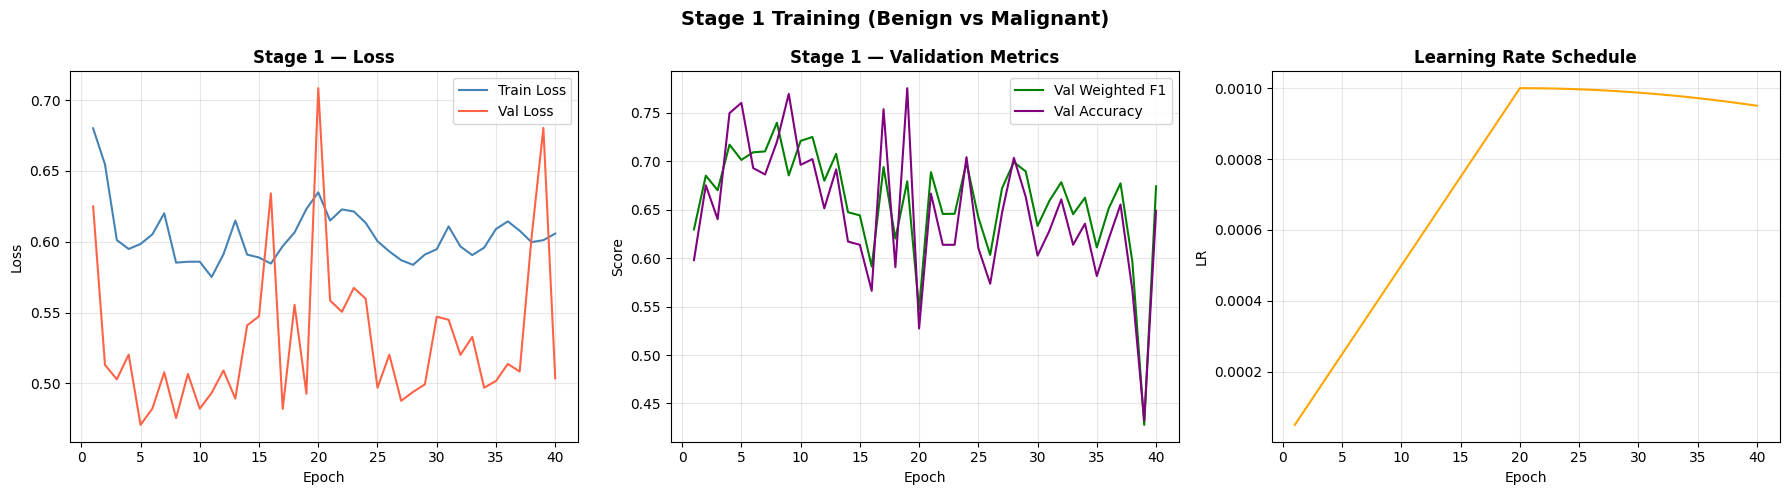

Saved: figures/stage1_training_curves.png


In [17]:
# ── Plot Stage 1 training curves ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

epochs_range = range(1, EPOCHS_STAGE1 + 1)

axes[0].plot(epochs_range, history_s1['train_loss'], label='Train Loss', color='steelblue')
axes[0].plot(epochs_range, history_s1['val_loss'],   label='Val Loss',   color='tomato')
axes[0].set_title('Stage 1 — Loss', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history_s1['val_f1'],  label='Val Weighted F1', color='green')
axes[1].plot(epochs_range, history_s1['val_acc'], label='Val Accuracy',    color='purple')
axes[1].set_title('Stage 1 — Validation Metrics', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Score')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

axes[2].plot(epochs_range, history_s1['lr'], color='orange')
axes[2].set_title('Learning Rate Schedule', fontweight='bold')
axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('LR')
axes[2].grid(True, alpha=0.3)

plt.suptitle('Stage 1 Training (Benign vs Malignant)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'stage1_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures/stage1_training_curves.png')

In [18]:
# ── Load best Stage 1 checkpoint before Stage 2 ──────────────────────────────
checkpoint = torch.load(CHECKPOINTS_DIR / 'best_stage1.pt', map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
print(f'Loaded best Stage 1 checkpoint (epoch {checkpoint["epoch"]}, Val F1={checkpoint["val_f1"]:.4f})')

# ── Freeze backbone for Stage 2 ───────────────────────────────────────────────
# We freeze the backbone parameters so Stage 2 training only updates the Stage 2 head.
# This prevents the backbone from forgetting Stage 1 discriminative features.

for param in model.backbone.parameters():
    param.requires_grad = False
for param in model.stage1_head.parameters():
    param.requires_grad = False

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable parameters for Stage 2: {trainable:,}  (Stage 2 head only)')

Loaded best Stage 1 checkpoint (epoch 8, Val F1=0.7399)
Trainable parameters for Stage 2: 1,283  (Stage 2 head only)


In [19]:
# ── Stage 2 Training (malignant subtype classification) ───────────────────────
# We train ONLY on malignant images. The dataloader still yields all images,
# but we filter to malignant using the s2_label mask (s2_label >= 0).

criterion_s2 = nn.CrossEntropyLoss(weight=s2_weights)
optimizer_s2 = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LR_STAGE2, weight_decay=WEIGHT_DECAY
)
scaler_s2    = GradScaler()
scheduler_s2 = get_lr_scheduler(optimizer_s2, 3, EPOCHS_STAGE2, len(train_loader))

history_s2 = {'train_loss': [], 'val_loss': [], 'val_f1': [], 'val_acc': []}
best_s2_f1 = 0.0

print(f'Starting Stage 2 training for {EPOCHS_STAGE2} epochs (malignant subset only)...')

for epoch in range(1, EPOCHS_STAGE2 + 1):
    model.train()
    epoch_loss  = 0.0
    num_samples = 0

    optimizer_s2.zero_grad()
    accum_count = 0

    for step, (imgs, _, s2_labels) in enumerate(train_loader):
        mask = s2_labels >= 0
        if mask.sum() == 0:
            continue

        imgs      = imgs[mask].to(device, non_blocking=True)
        s2_labels = s2_labels[mask].to(device, non_blocking=True)

        with autocast():
            _, logits2 = model(imgs)
            loss = criterion_s2(logits2, s2_labels) / ACCUM_STEPS

        scaler_s2.scale(loss).backward()
        accum_count += 1

        if accum_count % ACCUM_STEPS == 0 or (step + 1) == len(train_loader):
            scaler_s2.unscale_(optimizer_s2)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler_s2.step(optimizer_s2)
            scaler_s2.update()
            optimizer_s2.zero_grad()
            scheduler_s2.step()

        epoch_loss  += loss.item() * ACCUM_STEPS * len(imgs)
        num_samples += len(imgs)

    train_loss = epoch_loss / max(num_samples, 1)
    val_loss, val_f1, val_acc, _, _ = validate_stage2(model, val_loader)

    history_s2['train_loss'].append(train_loss)
    history_s2['val_loss'].append(val_loss)
    history_s2['val_f1'].append(val_f1)
    history_s2['val_acc'].append(val_acc)

    if val_f1 > best_s2_f1:
        best_s2_f1 = val_f1
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'val_f1': val_f1,
        }, CHECKPOINTS_DIR / 'best_stage2.pt')

    if epoch % 5 == 0 or epoch == 1:
        print(f'Epoch [{epoch:3d}/{EPOCHS_STAGE2}] '
              f'Train Loss: {train_loss:.4f} | '
              f'Val Loss: {val_loss:.4f} | '
              f'Val F1: {val_f1:.4f} | '
              f'Val Acc: {val_acc:.4f}')

print(f'\nBest Stage 2 Val Weighted F1: {best_s2_f1:.4f}')
print(f'Checkpoint saved to: checkpoints/best_stage2.pt')

Starting Stage 2 training for 25 epochs (malignant subset only)...
Epoch [  1/25] Train Loss: 1.0526 | Val Loss: 0.9958 | Val F1: 0.3991 | Val Acc: 0.5575
Epoch [  5/25] Train Loss: 0.9767 | Val Loss: 0.8961 | Val F1: 0.4619 | Val Acc: 0.5870
Epoch [ 10/25] Train Loss: 0.9051 | Val Loss: 0.8024 | Val F1: 0.5252 | Val Acc: 0.6254
Epoch [ 15/25] Train Loss: 0.8829 | Val Loss: 0.7313 | Val F1: 0.6616 | Val Acc: 0.7021
Epoch [ 20/25] Train Loss: 0.8666 | Val Loss: 0.7255 | Val F1: 0.6475 | Val Acc: 0.6903
Epoch [ 25/25] Train Loss: 0.8473 | Val Loss: 0.7202 | Val F1: 0.6627 | Val Acc: 0.6991

Best Stage 2 Val Weighted F1: 0.6946
Checkpoint saved to: checkpoints/best_stage2.pt


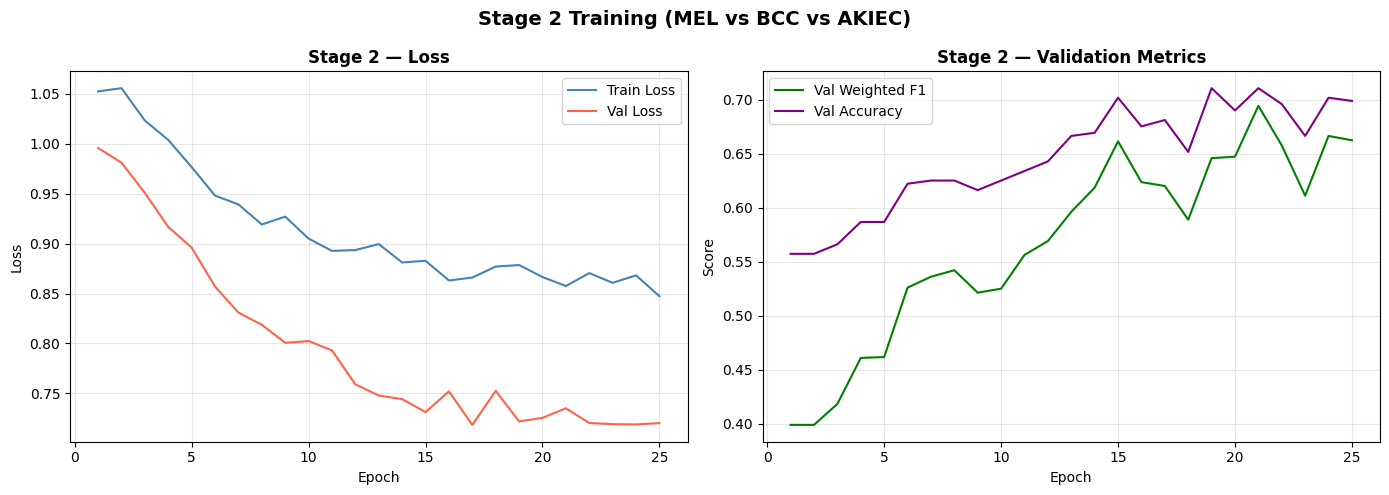

Saved: figures/stage2_training_curves.png


In [20]:
# ── Plot Stage 2 training curves ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, EPOCHS_STAGE2 + 1)

axes[0].plot(epochs_range, history_s2['train_loss'], label='Train Loss', color='steelblue')
axes[0].plot(epochs_range, history_s2['val_loss'],   label='Val Loss',   color='tomato')
axes[0].set_title('Stage 2 — Loss', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history_s2['val_f1'],  label='Val Weighted F1', color='green')
axes[1].plot(epochs_range, history_s2['val_acc'], label='Val Accuracy',    color='purple')
axes[1].set_title('Stage 2 — Validation Metrics', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Score')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.suptitle('Stage 2 Training (MEL vs BCC vs AKIEC)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'stage2_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures/stage2_training_curves.png')

In [21]:
# ── Optional: Joint fine-tuning (backbone + both heads) ───────────────────────
# After Stage 2 head converges, unfreeze everything and fine-tune with a small LR.
# This can improve final performance but risks catastrophic forgetting if LR is too high.

# Load best Stage 2 checkpoint
checkpoint = torch.load(CHECKPOINTS_DIR / 'best_stage2.pt', map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
print(f'Loaded Stage 2 checkpoint (epoch {checkpoint["epoch"]})')

# Unfreeze ALL parameters
for param in model.parameters():
    param.requires_grad = True

optimizer_ft = optim.AdamW(model.parameters(), lr=LR_FINETUNE, weight_decay=WEIGHT_DECAY)
scaler_ft    = GradScaler()
scheduler_ft = get_lr_scheduler(optimizer_ft, 2, EPOCHS_FINETUNE, len(train_loader))

best_ft_f1 = 0.0
history_ft = {'train_loss_s1': [], 'val_f1_s1': [], 'val_f1_s2': []}

print(f'\nStarting joint fine-tuning for {EPOCHS_FINETUNE} epochs...')

for epoch in range(1, EPOCHS_FINETUNE + 1):
    model.train()
    total_loss  = 0.0
    num_batches = 0
    optimizer_ft.zero_grad()

    for step, (imgs, s1_labels, s2_labels) in enumerate(train_loader):
        imgs      = imgs.to(device, non_blocking=True)
        s1_labels = s1_labels.to(device, non_blocking=True)

        mask      = s2_labels >= 0
        s2_imgs   = imgs[mask]
        s2_lbl    = s2_labels[mask].to(device)

        with autocast():
            logits1, logits2_all = model(imgs)
            loss_s1 = criterion_s1(logits1, s1_labels)

            if mask.sum() > 0:
                loss_s2 = criterion_s2(logits2_all[mask], s2_lbl)
                loss = (loss_s1 + loss_s2) / (2 * ACCUM_STEPS)
            else:
                loss = loss_s1 / ACCUM_STEPS

        scaler_ft.scale(loss).backward()

        if (step + 1) % ACCUM_STEPS == 0 or (step + 1) == len(train_loader):
            scaler_ft.unscale_(optimizer_ft)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler_ft.step(optimizer_ft)
            scaler_ft.update()
            optimizer_ft.zero_grad()
            scheduler_ft.step()

        total_loss  += loss.item() * ACCUM_STEPS
        num_batches += 1

    train_loss = total_loss / num_batches
    _, val_f1_s1, val_acc_s1, _, _ = validate_stage1(model, val_loader)
    _, val_f1_s2, val_acc_s2, _, _ = validate_stage2(model, val_loader)

    history_ft['train_loss_s1'].append(train_loss)
    history_ft['val_f1_s1'].append(val_f1_s1)
    history_ft['val_f1_s2'].append(val_f1_s2)

    combined_f1 = (val_f1_s1 + val_f1_s2) / 2
    if combined_f1 > best_ft_f1:
        best_ft_f1 = combined_f1
        torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(),
                    'val_f1_s1': val_f1_s1, 'val_f1_s2': val_f1_s2},
                   CHECKPOINTS_DIR / 'best_finetuned.pt')

    if epoch % 5 == 0 or epoch == 1:
        print(f'Epoch [{epoch:2d}/{EPOCHS_FINETUNE}] '
              f'S1 F1: {val_f1_s1:.4f} | S2 F1: {val_f1_s2:.4f} | '
              f'S1 Acc: {val_acc_s1:.4f} | S2 Acc: {val_acc_s2:.4f}')

print(f'\nFine-tuning complete. Best combined F1: {best_ft_f1:.4f}')
print('Checkpoint saved to: checkpoints/best_finetuned.pt')

Loaded Stage 2 checkpoint (epoch 21)

Starting joint fine-tuning for 15 epochs...
Epoch [ 1/15] S1 F1: 0.7631 | S2 F1: 0.6700 | S1 Acc: 0.7538 | S2 Acc: 0.7021
Epoch [ 5/15] S1 F1: 0.7547 | S2 F1: 0.6389 | S1 Acc: 0.7380 | S2 Acc: 0.6844
Epoch [10/15] S1 F1: 0.6958 | S2 F1: 0.7113 | S1 Acc: 0.6686 | S2 Acc: 0.7286
Epoch [15/15] S1 F1: 0.7719 | S2 F1: 0.6868 | S1 Acc: 0.7584 | S2 Acc: 0.7109

Fine-tuning complete. Best combined F1: 0.7440
Checkpoint saved to: checkpoints/best_finetuned.pt


---
## Section 6: Evaluation on Test Set

We load the best fine-tuned checkpoint and evaluate on the held-out test set.  
Primary metric is **Sensitivity/Recall** — in a clinical skin lesion screening context, a false negative (missed malignant lesion) is far more harmful than a false positive. We therefore optimise and report sensitivity first.

We also report:
- **Weighted F1**: Handles class imbalance
- **Specificity**: True negative rate (clinically relevant for over-referral)
- **Overall Accuracy**: For comparison with MobileNetV2 teammate
- **Per-class precision and recall**
- **Confusion matrices** for both stages
- **ROC curves** with AUC

In [22]:
# ── Load best model for evaluation ────────────────────────────────────────────
# Try fine-tuned first, fall back to stage2 checkpoint
ft_ckpt = CHECKPOINTS_DIR / 'best_finetuned.pt'
s2_ckpt = CHECKPOINTS_DIR / 'best_stage2.pt'

if ft_ckpt.exists():
    ckpt = torch.load(ft_ckpt, map_location=device)
    print(f'Using fine-tuned checkpoint (epoch {ckpt["epoch"]})')
else:
    ckpt = torch.load(s2_ckpt, map_location=device)
    print(f'Using Stage 2 checkpoint (epoch {ckpt["epoch"]})')

model.load_state_dict(ckpt['model_state_dict'])
model.eval()
print('Model loaded for evaluation.')

Using fine-tuned checkpoint (epoch 9)
Model loaded for evaluation.


In [23]:
# ── Collect all test predictions ──────────────────────────────────────────────

@torch.no_grad()
def run_full_evaluation(model, loader):
    """
    Run the two-stage pipeline on all test images.
    Returns predictions, probabilities, and ground-truth labels.
    """
    model.eval()

    s1_true, s1_pred, s1_probs = [], [], []
    s2_true, s2_pred, s2_probs = [], [], []

    for imgs, s1_labels, s2_labels in loader:
        imgs = imgs.to(device)

        with autocast():
            logits1, logits2 = model(imgs)

        probs1 = torch.softmax(logits1, dim=1)  # (B, 2)
        probs2 = torch.softmax(logits2, dim=1)  # (B, 3)
        pred1  = probs1.argmax(dim=1)
        pred2  = probs2.argmax(dim=1)

        s1_true.extend(s1_labels.numpy())
        s1_pred.extend(pred1.cpu().numpy())
        s1_probs.extend(probs1.cpu().numpy())

        # Stage 2: only collect where ground truth is malignant
        mask = s2_labels >= 0
        if mask.sum() > 0:
            s2_true.extend(s2_labels[mask].numpy())
            s2_pred.extend(pred2[mask.to(device)].cpu().numpy())
            s2_probs.extend(probs2[mask.to(device)].cpu().numpy())

    return (
        np.array(s1_true), np.array(s1_pred), np.array(s1_probs),
        np.array(s2_true), np.array(s2_pred), np.array(s2_probs)
    )


s1_true, s1_pred, s1_probs, s2_true, s2_pred, s2_probs = run_full_evaluation(model, test_loader)

print(f'Stage 1 test samples: {len(s1_true)}')
print(f'Stage 2 test samples (malignant only): {len(s2_true)}')

Stage 1 test samples: 1519
Stage 2 test samples (malignant only): 259


In [24]:
# ── Stage 1 Metrics ─────────────────────────────────────────────────────────────────────────

def compute_all_metrics(y_true, y_pred, y_probs, class_names, stage_name):
    n_classes = len(class_names)

    acc   = accuracy_score(y_true, y_pred)
    wf1   = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    prec  = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec   = recall_score(y_true, y_pred, average='weighted', zero_division=0)

    sep = '=' * 60
    print()
    print(sep)
    print(f' {stage_name} — Test Set Results')
    print(sep)
    print(f'  Overall Accuracy       : {acc:.4f}')
    print(f'  Weighted F1 Score      : {wf1:.4f}')
    print(f'  Weighted Precision     : {prec:.4f}')
    print(f'  Weighted Recall (Sens) : {rec:.4f}')

    # Per-class metrics
    print('  Per-class metrics:')
    report = classification_report(
        y_true, y_pred, target_names=class_names,
        digits=4, zero_division=0
    )
    print(report)

    # Specificity per class
    cm = confusion_matrix(y_true, y_pred, labels=list(range(n_classes)))
    print('  Specificity per class:')
    for i, cls in enumerate(class_names):
        tn = cm.sum() - (cm[i, :].sum() + cm[:, i].sum() - cm[i, i])
        fp = cm[:, i].sum() - cm[i, i]
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0
        print(f'    {cls:8s}: {spec:.4f}')

    return acc, wf1, prec, rec, cm


s1_acc, s1_wf1, s1_prec, s1_rec, s1_cm = compute_all_metrics(
    s1_true, s1_pred, s1_probs, ['Benign', 'Malignant'], 'STAGE 1'
)


 STAGE 1 — Test Set Results
  Overall Accuracy       : 0.7459
  Weighted F1 Score      : 0.7686
  Weighted Precision     : 0.8095
  Weighted Recall (Sens) : 0.7459
  Per-class metrics:
              precision    recall  f1-score   support

      Benign     0.9031    0.7770    0.8353      1260
   Malignant     0.3540    0.5946    0.4438       259

    accuracy                         0.7459      1519
   macro avg     0.6286    0.6858    0.6396      1519
weighted avg     0.8095    0.7459    0.7686      1519

  Specificity per class:
    Benign  : 0.5946
    Malignant: 0.7770


In [25]:
# ── Stage 2 Metrics ───────────────────────────────────────────────────────────
s2_acc, s2_wf1, s2_prec, s2_rec, s2_cm = compute_all_metrics(
    s2_true, s2_pred, s2_probs, MAL_SUBCLASS_NAMES, 'STAGE 2'
)


 STAGE 2 — Test Set Results
  Overall Accuracy       : 0.7529
  Weighted F1 Score      : 0.7406
  Weighted Precision     : 0.7354
  Weighted Recall (Sens) : 0.7529
  Per-class metrics:
              precision    recall  f1-score   support

         MEL     0.8545    0.9338    0.8924       151
         BCC     0.5968    0.5968    0.5968        62
       AKIEC     0.5312    0.3696    0.4359        46

    accuracy                         0.7529       259
   macro avg     0.6609    0.6334    0.6417       259
weighted avg     0.7354    0.7529    0.7406       259

  Specificity per class:
    MEL     : 0.7778
    BCC     : 0.8731
    AKIEC   : 0.9296


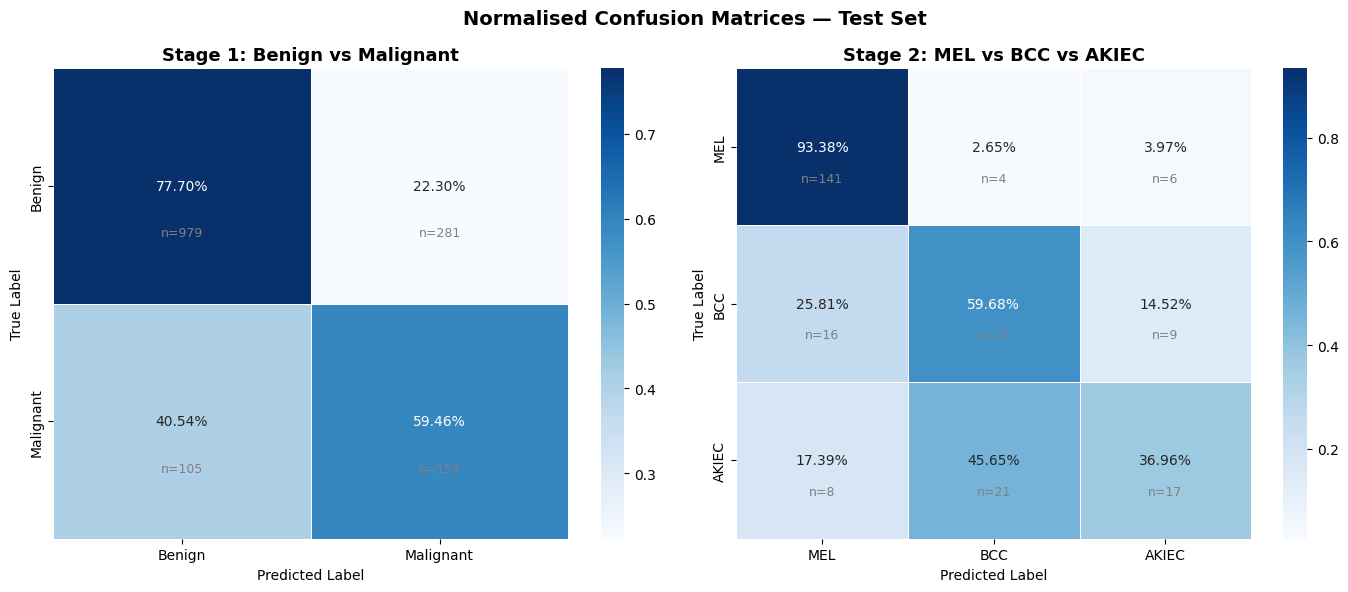

Saved: figures/confusion_matrices.png


In [26]:
# ── Confusion Matrices ────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (cm, labels, title) in zip(axes, [
    (s1_cm, ['Benign', 'Malignant'], 'Stage 1: Benign vs Malignant'),
    (s2_cm, MAL_SUBCLASS_NAMES,      'Stage 2: MEL vs BCC vs AKIEC'),
]):
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    sns.heatmap(
        cm_norm, annot=True, fmt='.2%', cmap='Blues',
        xticklabels=labels, yticklabels=labels,
        ax=ax, linewidths=0.5
    )
    # Overlay raw counts
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j + 0.5, i + 0.7, f'n={cm[i,j]}',
                    ha='center', va='center', fontsize=9, color='gray')
    ax.set_title(title, fontweight='bold', fontsize=13)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.suptitle('Normalised Confusion Matrices — Test Set', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures/confusion_matrices.png')

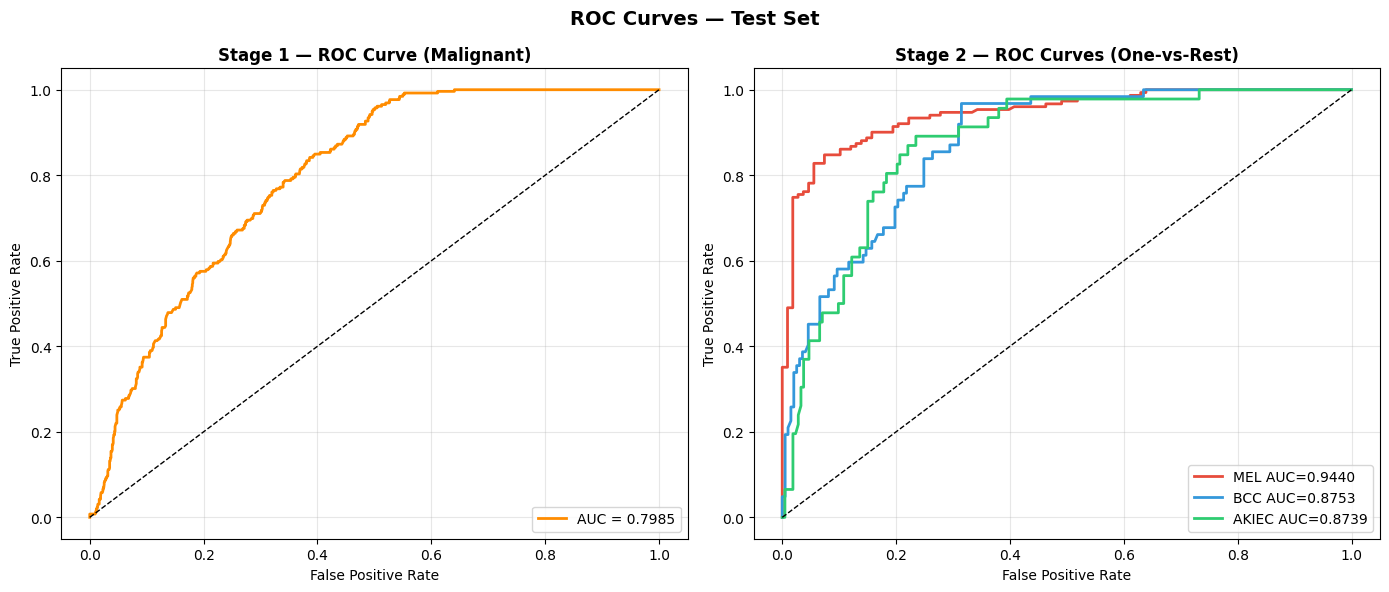

Saved: figures/roc_curves.png


In [27]:
# ── ROC Curves ────────────────────────────────────────────────────────────────
from sklearn.preprocessing import label_binarize

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Stage 1 ROC
ax = axes[0]
fpr, tpr, _ = roc_curve(s1_true, s1_probs[:, 1])
roc_auc = auc(fpr, tpr)
ax.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.4f}')
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('Stage 1 — ROC Curve (Malignant)', fontweight='bold')
ax.legend(loc='lower right'); ax.grid(True, alpha=0.3)

# Stage 2 ROC (one-vs-rest per class)
ax = axes[1]
colors = ['#e74c3c', '#3498db', '#2ecc71']
s2_binarized = label_binarize(s2_true, classes=[0, 1, 2])
for i, (cls_name, color) in enumerate(zip(MAL_SUBCLASS_NAMES, colors)):
    fpr, tpr, _ = roc_curve(s2_binarized[:, i], s2_probs[:, i])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, lw=2, label=f'{cls_name} AUC={roc_auc:.4f}')
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('Stage 2 — ROC Curves (One-vs-Rest)', fontweight='bold')
ax.legend(loc='lower right'); ax.grid(True, alpha=0.3)

plt.suptitle('ROC Curves — Test Set', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures/roc_curves.png')

---
## Section 7: Attention Rollout Visualisation

### What is Attention Rollout?

Attention Rollout (Abnar & Zuidema, 2020) is an explainability technique for Transformers that aggregates attention maps across all layers to estimate which input patches the model attended to when making its final decision.

### Algorithm

For each transformer block $l$, we have an attention matrix $A^{(l)}$ of shape $\text{(heads, N, N)}$ where $N = 197$ tokens (1 CLS + 196 patches).

1. Average over heads: $\bar{A}^{(l)} = \frac{1}{H}\sum_h A^{(l)}_h$
2. Add residual connection: $\tilde{A}^{(l)} = \bar{A}^{(l)} + I$
3. Re-normalise rows to sum to 1
4. Multiply across layers: $R = \tilde{A}^{(L)} \cdot \tilde{A}^{(L-1)} \cdots \tilde{A}^{(1)}$
5. Extract CLS row: $\text{mask} = R[0, 1:]$ — the CLS token's attention to each of the 196 patches
6. Reshape to 14×14 and upsample to 224×224

In [28]:
# ── Attention Rollout Implementation ──────────────────────────────────────────

def attention_rollout(model, image_tensor):
    """
    Compute Attention Rollout for a single image.

    Args:
        model: TwoStageViT with attention weights stored after forward pass
        image_tensor: (1, 3, 224, 224) tensor on the correct device

    Returns:
        rollout_map: (224, 224) numpy array — normalised attention heatmap
        stage1_pred: int — Stage 1 prediction (0=benign, 1=malignant)
        stage2_pred: int — Stage 2 prediction (0=MEL, 1=BCC, 2=AKIEC)
    """
    model.eval()

    with torch.no_grad():
        logits1, logits2 = model(image_tensor)
        stage1_pred = logits1.argmax(dim=1).item()
        stage2_pred = logits2.argmax(dim=1).item()

    # Retrieve attention weights from all transformer blocks
    # Each weight tensor: (1, num_heads, 197, 197)
    attn_list = model.get_attention_weights()  # List of (1, H, N, N)

    # Rollout accumulation
    eye = torch.eye(197, device=device)  # Identity for residual
    rollout = eye.unsqueeze(0)            # (1, 197, 197)

    for attn in attn_list:
        # Average over heads → (1, 197, 197)
        attn_avg = attn.mean(dim=1)

        # Add residual connection (captures skip-connection information flow)
        attn_aug = attn_avg + eye

        # Re-normalise rows (so each token's attention sums to 1)
        attn_aug = attn_aug / attn_aug.sum(dim=-1, keepdim=True)

        # Matrix multiply to propagate attention through layers
        rollout = torch.bmm(attn_aug, rollout)

    # Extract CLS token's attention to all 196 patch tokens (skip index 0 = CLS)
    cls_attn = rollout[0, 0, 1:]  # (196,)

    # Reshape to 14×14 spatial grid
    mask = cls_attn.cpu().numpy().reshape(14, 14)

    # Normalise to [0, 1]
    mask = (mask - mask.min()) / (mask.max() - mask.min() + 1e-8)

    # Upsample to 224×224 using PIL
    mask_img = Image.fromarray((mask * 255).astype(np.uint8)).resize(
        (224, 224), Image.BILINEAR
    )
    rollout_map = np.array(mask_img) / 255.0

    return rollout_map, stage1_pred, stage2_pred


def denormalize(tensor):
    """Undo ImageNet normalisation for display."""
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (tensor * std + mean).clamp(0, 1)


print('Attention Rollout functions defined.')

Attention Rollout functions defined.


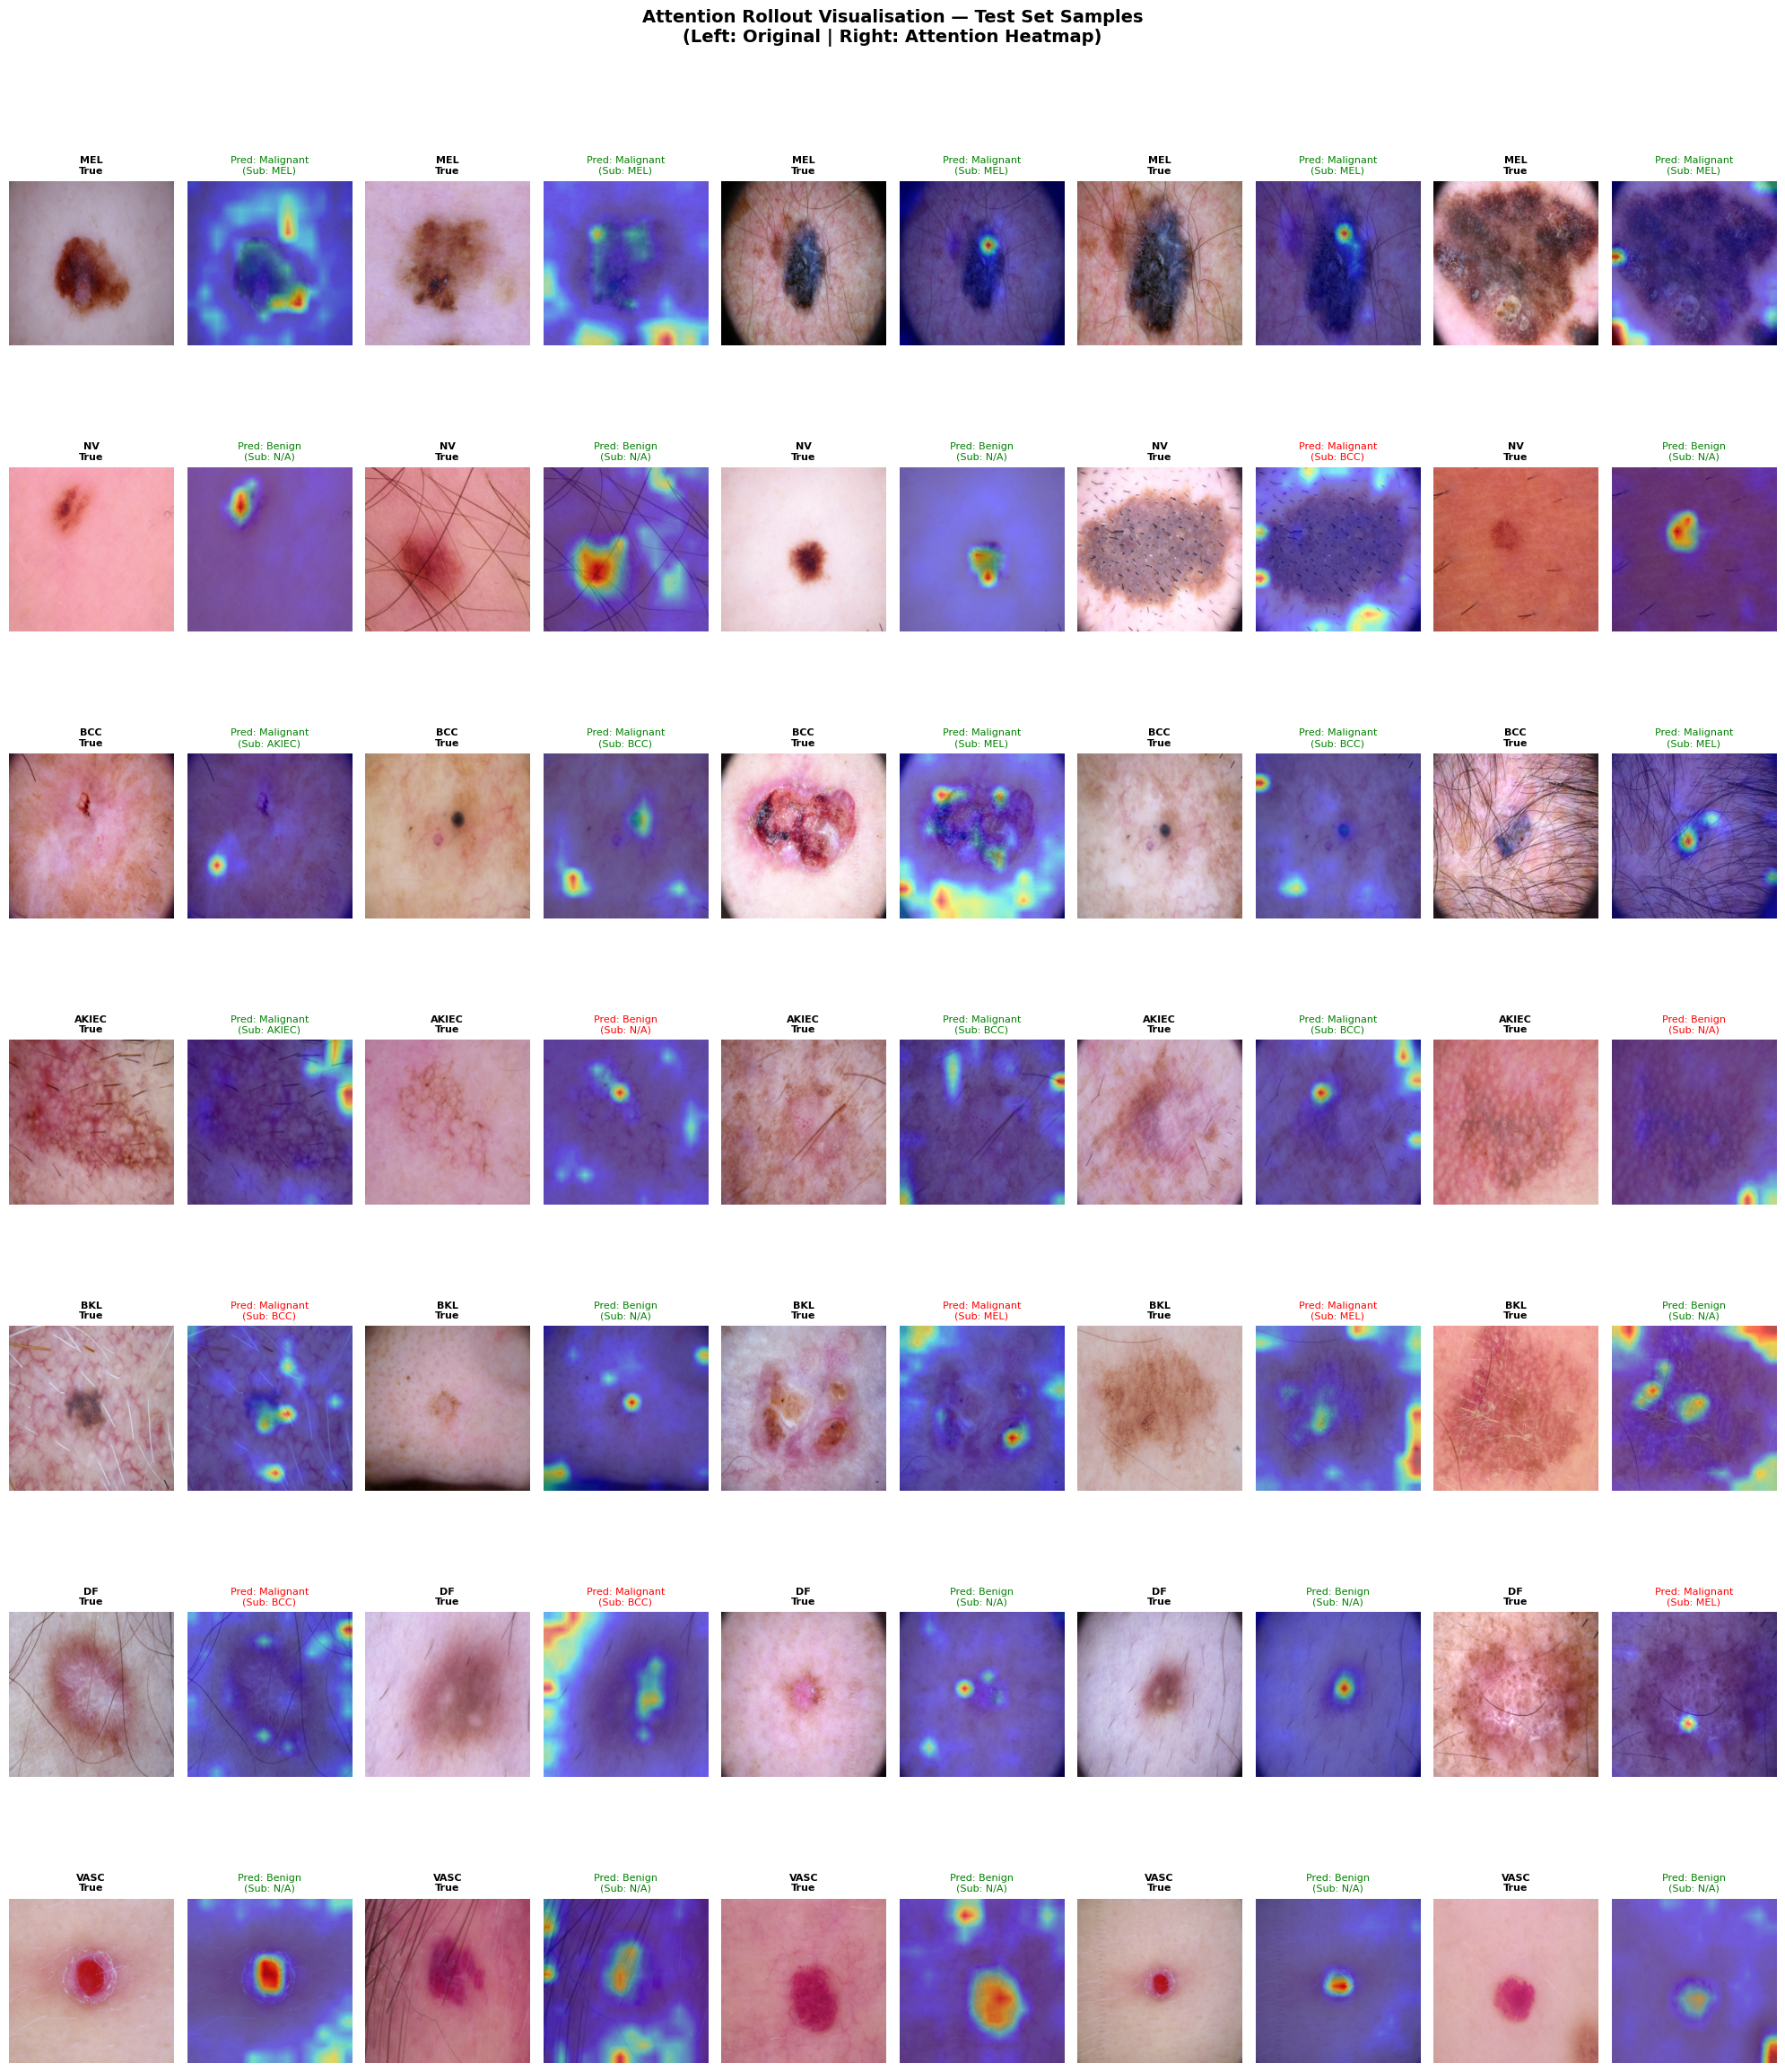

Saved: figures/attention_rollout_all_classes.png


In [29]:
# ── Generate attention maps for 5 examples per class ─────────────────────────
# We sample from the test set, run attention rollout, and overlay on original image.

ATTN_SAMPLES_PER_CLASS = 5
STAGE1_CLASS_NAMES     = ['Benign', 'Malignant']

fig_rows = len(CLASS_NAMES)
fig_cols = ATTN_SAMPLES_PER_CLASS * 2   # original + heatmap pairs

fig, axes = plt.subplots(fig_rows, fig_cols, figsize=(4 * ATTN_SAMPLES_PER_CLASS, 3.5 * fig_rows))

for row_idx, cls_name in enumerate(CLASS_NAMES):
    cls_df   = test_df[test_df['dx'] == cls_name]
    n_avail  = min(ATTN_SAMPLES_PER_CLASS, len(cls_df))
    samples  = cls_df.sample(n_avail, random_state=SEED)

    for col_idx in range(ATTN_SAMPLES_PER_CLASS):
        orig_ax  = axes[row_idx, col_idx * 2]
        heat_ax  = axes[row_idx, col_idx * 2 + 1]

        if col_idx < n_avail:
            row_data = samples.iloc[col_idx]

            # Load and transform image
            raw_img = Image.open(row_data['filepath']).convert('RGB')
            img_t   = val_transform(raw_img).unsqueeze(0).to(device)

            # Compute attention rollout
            attn_map, s1_p, s2_p = attention_rollout(model, img_t)

            # Display original image
            display_img = np.array(raw_img.resize((224, 224)))
            orig_ax.imshow(display_img)
            orig_ax.set_title(f'{cls_name.upper()}\nTrue', fontsize=8, fontweight='bold')
            orig_ax.axis('off')

            # Display heatmap overlay
            heat_ax.imshow(display_img)
            im = heat_ax.imshow(attn_map, cmap='jet', alpha=0.5, vmin=0, vmax=1)
            s2_label = MAL_SUBCLASS_NAMES[s2_p] if s1_p == 1 else 'N/A'
            heat_ax.set_title(
                f'Pred: {STAGE1_CLASS_NAMES[s1_p]}\n(Sub: {s2_label})',
                fontsize=8, color='green' if (
                    (s1_p == 0) == (cls_name in BENIGN_CLASSES)
                ) else 'red'
            )
            heat_ax.axis('off')
        else:
            orig_ax.axis('off')
            heat_ax.axis('off')

plt.suptitle('Attention Rollout Visualisation — Test Set Samples\n'
             '(Left: Original | Right: Attention Heatmap)', 
             fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(FIGURES_DIR / 'attention_rollout_all_classes.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved: figures/attention_rollout_all_classes.png')

In [30]:
# ── Detailed attention maps: one figure per class (5 examples, larger view) ───

for cls_name in CLASS_NAMES:
    cls_df  = test_df[test_df['dx'] == cls_name]
    n_avail = min(ATTN_SAMPLES_PER_CLASS, len(cls_df))
    samples = cls_df.sample(n_avail, random_state=SEED)

    fig, axes = plt.subplots(2, n_avail, figsize=(4 * n_avail, 8))
    if n_avail == 1:
        axes = axes.reshape(2, 1)

    for col_idx, (_, row_data) in enumerate(samples.iterrows()):
        raw_img = Image.open(row_data['filepath']).convert('RGB')
        img_t   = val_transform(raw_img).unsqueeze(0).to(device)
        attn_map, s1_p, s2_p = attention_rollout(model, img_t)

        display_img = np.array(raw_img.resize((224, 224)))

        axes[0, col_idx].imshow(display_img)
        axes[0, col_idx].set_title(f'Original {col_idx+1}', fontsize=10)
        axes[0, col_idx].axis('off')

        axes[1, col_idx].imshow(display_img)
        axes[1, col_idx].imshow(attn_map, cmap='jet', alpha=0.55, vmin=0, vmax=1)
        s1_label = STAGE1_CLASS_NAMES[s1_p]
        s2_label = MAL_SUBCLASS_NAMES[s2_p] if s1_p == 1 else '—'
        correct  = (s1_p == 0) == (cls_name in BENIGN_CLASSES)
        axes[1, col_idx].set_title(
            f'{s1_label} / {s2_label}',
            fontsize=10, color='green' if correct else 'red', fontweight='bold'
        )
        axes[1, col_idx].axis('off')

    plt.suptitle(f'Attention Rollout — Class: {cls_name.upper()}',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    save_path = FIGURES_DIR / f'attention_{cls_name}.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.close()
    print(f'Saved: figures/attention_{cls_name}.png')

print('All per-class attention maps saved.')

Saved: figures/attention_mel.png
Saved: figures/attention_nv.png
Saved: figures/attention_bcc.png
Saved: figures/attention_akiec.png
Saved: figures/attention_bkl.png
Saved: figures/attention_df.png
Saved: figures/attention_vasc.png
All per-class attention maps saved.


---
## Section 8: Results Summary

Final summary table formatted for direct comparison with the MobileNetV2 teammate's results.  
Both models were evaluated on the same held-out test set with the same metrics.

In [31]:
# ── Compute final metrics for summary table ────────────────────────────────────

def compute_sensitivity_specificity(y_true, y_pred, n_classes):
    """Per-class sensitivity and specificity."""
    cm = confusion_matrix(y_true, y_pred, labels=list(range(n_classes)))
    results = {}
    for i in range(n_classes):
        tp  = cm[i, i]
        fn  = cm[i, :].sum() - tp
        fp  = cm[:, i].sum() - tp
        tn  = cm.sum() - tp - fn - fp
        sens = tp / (tp + fn) if (tp + fn) > 0 else 0
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0
        results[i] = {'sensitivity': sens, 'specificity': spec, 'tp': tp, 'fn': fn, 'fp': fp, 'tn': tn}
    return results


s1_ss = compute_sensitivity_specificity(s1_true, s1_pred, 2)
s2_ss = compute_sensitivity_specificity(s2_true, s2_pred, 3)

print('\n' + '='*70)
print('  FINAL RESULTS SUMMARY — ViT from Scratch (HAM10000)')
print('='*70)
print('\n[STAGE 1: Benign vs Malignant]')
print(f'  Overall Accuracy         : {s1_acc:.4f}')
print(f'  Weighted F1 Score        : {s1_wf1:.4f}')
print(f'  Weighted Precision       : {s1_prec:.4f}')
print(f'  Weighted Recall/Sens.    : {s1_rec:.4f}')
print(f'  Malignant Sensitivity    : {s1_ss[1]["sensitivity"]:.4f}  ← (TP rate for cancer detection)')
print(f'  Malignant Specificity    : {s1_ss[1]["specificity"]:.4f}')
print(f'  Benign Sensitivity       : {s1_ss[0]["sensitivity"]:.4f}')

print('\n[STAGE 2: MEL vs BCC vs AKIEC  (malignant subtypes)]')
print(f'  Overall Accuracy         : {s2_acc:.4f}')
print(f'  Weighted F1 Score        : {s2_wf1:.4f}')
print(f'  Weighted Precision       : {s2_prec:.4f}')
print(f'  Weighted Recall/Sens.    : {s2_rec:.4f}')
for i, cls in enumerate(MAL_SUBCLASS_NAMES):
    print(f'  {cls} Sensitivity       : {s2_ss[i]["sensitivity"]:.4f}')

print('\n[MODEL INFO]')
total_params = sum(p.numel() for p in model.parameters())
print(f'  Architecture             : ViT (embed=256, depth=6, heads=8)')
print(f'  Total Parameters         : {total_params:,} (~{total_params/1e6:.1f}M)')
print(f'  Training Strategy        : From scratch, two-stage hierarchical')
print(f'  Input Resolution         : 224×224, patch size 16×16')
print(f'  Training Epochs          : S1={EPOCHS_STAGE1}, S2={EPOCHS_STAGE2}, FT={EPOCHS_FINETUNE}')
print(f'  Effective Batch Size     : {BATCH_SIZE * ACCUM_STEPS}')
print(f'  Mixed Precision          : Yes (fp16)')
print('='*70)


  FINAL RESULTS SUMMARY — ViT from Scratch (HAM10000)

[STAGE 1: Benign vs Malignant]
  Overall Accuracy         : 0.7459
  Weighted F1 Score        : 0.7686
  Weighted Precision       : 0.8095
  Weighted Recall/Sens.    : 0.7459
  Malignant Sensitivity    : 0.5946  ← (TP rate for cancer detection)
  Malignant Specificity    : 0.7770
  Benign Sensitivity       : 0.7770

[STAGE 2: MEL vs BCC vs AKIEC  (malignant subtypes)]
  Overall Accuracy         : 0.7529
  Weighted F1 Score        : 0.7406
  Weighted Precision       : 0.7354
  Weighted Recall/Sens.    : 0.7529
  MEL Sensitivity       : 0.9338
  BCC Sensitivity       : 0.5968
  AKIEC Sensitivity       : 0.3696

[MODEL INFO]
  Architecture             : ViT (embed=256, depth=6, heads=8)
  Total Parameters         : 3,408,389 (~3.4M)
  Training Strategy        : From scratch, two-stage hierarchical
  Input Resolution         : 224×224, patch size 16×16
  Training Epochs          : S1=40, S2=25, FT=15
  Effective Batch Size     : 32
  

In [32]:
# ── Final metrics table as pandas DataFrame (comparison-ready) ────────────────

summary_data = {
    'Model': ['ViT (from scratch)', 'MobileNetV2 (← teammate)'],
    'Stage': ['S1 + S2', 'S1 + S2'],
    'S1 Accuracy':        [round(s1_acc, 4),  '—'],
    'S1 Weighted F1':     [round(s1_wf1, 4),  '—'],
    'S1 Malignant Sens.': [round(s1_ss[1]['sensitivity'], 4), '—'],
    'S1 Malignant Spec.': [round(s1_ss[1]['specificity'], 4), '—'],
    'S2 Accuracy':        [round(s2_acc, 4),  '—'],
    'S2 Weighted F1':     [round(s2_wf1, 4),  '—'],
    'Params (M)':         [round(total_params/1e6, 1), '—'],
}

summary_df = pd.DataFrame(summary_data)
print('\nComparison Table (fill in MobileNetV2 column with teammate results):')
print(summary_df.to_string(index=False))

# Save to CSV for easy sharing
summary_df.to_csv('results_summary.csv', index=False)
print('\nSaved: results_summary.csv')


Comparison Table (fill in MobileNetV2 column with teammate results):
                   Model   Stage S1 Accuracy S1 Weighted F1 S1 Malignant Sens. S1 Malignant Spec. S2 Accuracy S2 Weighted F1 Params (M)
      ViT (from scratch) S1 + S2      0.7459         0.7686             0.5946              0.777      0.7529         0.7406        3.4
MobileNetV2 (← teammate) S1 + S2           —              —                  —                  —           —              —          —

Saved: results_summary.csv


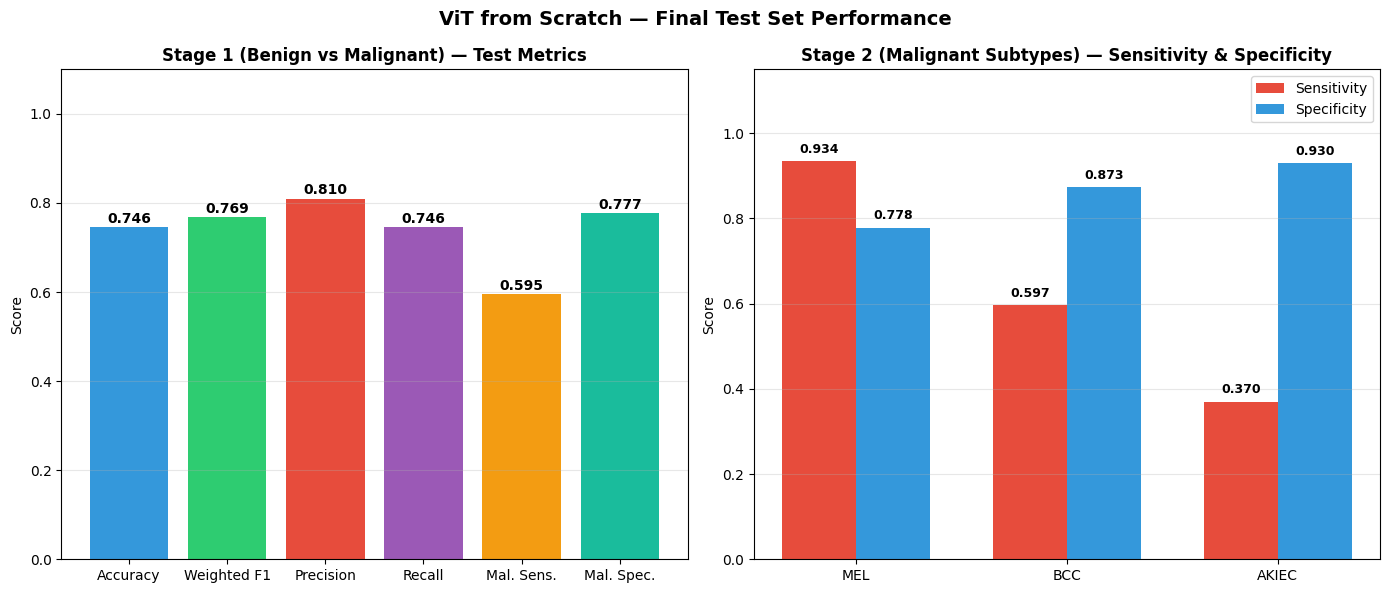

Saved: figures/final_metrics_summary.png

✓ All figures saved to figures/
✓ Model checkpoints saved to checkpoints/
✓ Results table saved to results_summary.csv

Notebook complete.


In [33]:
# ── Final summary visualisation ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Stage 1 metrics bar chart
s1_metrics = {
    'Accuracy':    s1_acc,
    'Weighted F1': s1_wf1,
    'Precision':   s1_prec,
    'Recall':      s1_rec,
    'Mal. Sens.':  s1_ss[1]['sensitivity'],
    'Mal. Spec.':  s1_ss[1]['specificity'],
}
colors = ['#3498db', '#2ecc71', '#e74c3c', '#9b59b6', '#f39c12', '#1abc9c']
bars = axes[0].bar(s1_metrics.keys(), s1_metrics.values(), color=colors)
axes[0].set_ylim(0, 1.1)
axes[0].set_title('Stage 1 (Benign vs Malignant) — Test Metrics', fontweight='bold')
axes[0].set_ylabel('Score')
for bar, val in zip(bars, s1_metrics.values()):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{val:.3f}', ha='center', fontsize=10, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

# Stage 2 per-class sensitivity
s2_sens = [s2_ss[i]['sensitivity'] for i in range(3)]
s2_spec = [s2_ss[i]['specificity'] for i in range(3)]
x = np.arange(3)
w = 0.35
axes[1].bar(x - w/2, s2_sens, w, label='Sensitivity', color='#e74c3c')
axes[1].bar(x + w/2, s2_spec, w, label='Specificity', color='#3498db')
axes[1].set_xticks(x)
axes[1].set_xticklabels(MAL_SUBCLASS_NAMES)
axes[1].set_ylim(0, 1.15)
axes[1].set_title('Stage 2 (Malignant Subtypes) — Sensitivity & Specificity', fontweight='bold')
axes[1].set_ylabel('Score')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)
for i, (s, sp) in enumerate(zip(s2_sens, s2_spec)):
    axes[1].text(i - w/2, s + 0.02, f'{s:.3f}', ha='center', fontsize=9, fontweight='bold')
    axes[1].text(i + w/2, sp + 0.02, f'{sp:.3f}', ha='center', fontsize=9, fontweight='bold')

plt.suptitle('ViT from Scratch — Final Test Set Performance', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'final_metrics_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures/final_metrics_summary.png')

print('\n✓ All figures saved to figures/')
print('✓ Model checkpoints saved to checkpoints/')
print('✓ Results table saved to results_summary.csv')
print('\nNotebook complete.')

---
## Section 9: Pipeline Evaluation (evaluation.py)

This section uses the shared `evaluation.py` module to compute macro F1, pipeline recall, Stage 1 leakage, and Stage 2 conditional accuracy — metrics that complement the weighted F1 / accuracy reported in Section 6.

In [ ]:
# ── Import shared evaluation module ─────────────────────────────────────────
import sys, os
sys.path.insert(0, str(Path('.').resolve()))
from evaluation import evaluate_stage1, evaluate_stage2, evaluate_pipeline

In [ ]:
# ── Stage 1 — extended metrics (Macro F1 + ROC-AUC) ─────────────────────────
s1_results = evaluate_stage1(s1_true, s1_pred, s1_probs)

In [ ]:
# ── Stage 2 — extended metrics (Macro F1 + per-class recall) ────────────────
s2_results = evaluate_stage2(s2_true, s2_pred, s2_probs)

In [ ]:
# ── Collect Stage 2 predictions for pipeline evaluation ──────────────────────
# For true pipeline evaluation, Stage 2 should only be judged on images
# where Stage 1 predicted malignant (Stage 1 TPs).
# Haruna's run_full_evaluation uses ground-truth malignant as the filter;
# here we use Stage 1 predicted malignant instead.

@torch.no_grad()
def run_pipeline_s2(model, loader):
    """Return s2 true/pred only for cases where Stage 1 predicted malignant."""
    model.eval()
    s2_true_pl, s2_pred_pl = [], []
    for imgs, s1_labels, s2_labels in loader:
        imgs = imgs.to(device)
        with autocast():
            logits1, logits2 = model(imgs)
        probs1 = torch.softmax(logits1, dim=1)
        probs2 = torch.softmax(logits2, dim=1)
        pred1  = probs1.argmax(dim=1).cpu()
        pred2  = probs2.argmax(dim=1).cpu()
        # Stage 1 TPs: predicted malignant AND ground truth is malignant
        mask = (pred1 == 1) & (s2_labels >= 0)
        if mask.sum() > 0:
            s2_true_pl.extend(s2_labels[mask].numpy())
            s2_pred_pl.extend(pred2[mask].numpy())
    return np.array(s2_true_pl), np.array(s2_pred_pl)

s2_true_pipeline, s2_pred_pipeline = run_pipeline_s2(model, test_loader)
print(f'Stage 1 TPs reaching Stage 2: {len(s2_true_pipeline)}')

In [ ]:
# ── Pipeline evaluation ──────────────────────────────────────────────────────
pipeline_results = evaluate_pipeline(s1_true, s1_pred, s2_true_pipeline, s2_pred_pipeline)

In [ ]:
# ── ViT efficiency summary ────────────────────────────────────────────────────
import time

# Model file size
ckpt_path = CHECKPOINTS_DIR / 'best_finetuned.pt'
if not ckpt_path.exists():
    ckpt_path = CHECKPOINTS_DIR / 'best_stage2.pt'
size_mb = os.path.getsize(ckpt_path) / (1024 * 1024) if ckpt_path.exists() else None

# Inference time (CPU, 100 runs, single image)
model_cpu = model.cpu().eval()
dummy_img  = torch.zeros(1, 3, 224, 224)
with torch.no_grad():
    for _ in range(10):          # warmup
        model_cpu(dummy_img)
    t0 = time.time()
    for _ in range(100):
        model_cpu(dummy_img)
    avg_ms = (time.time() - t0) / 100 * 1000
model.to(device)                 # move back

print("=" * 45)
print("  ViT EFFICIENCY SUMMARY")
print("=" * 45)
print(f"  Parameters:        {total_params:,}  (~{total_params/1e6:.1f}M)")
if size_mb:
    print(f"  Model size:        {size_mb:.1f} MB")
else:
    est_mb = total_params * 4 / (1024 * 1024)
    print(f"  Model size (est):  {est_mb:.1f} MB  (checkpoint not found)")
print(f"  Inference time:    {avg_ms:.1f} ms/image (CPU, single image)")
print("=" * 45)